### Étape 1 : Chargement et découverte des données

In [488]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)


df=pd.read_csv("PJME_hourly.csv")
df.head() 

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


In [489]:
print(df.dtypes)  #Datetime is  str 

Datetime        str
PJME_MW     float64
dtype: object


In [490]:
df["Datetime"]=pd.to_datetime(df["Datetime"])
print(df.dtypes)

Datetime    datetime64[us]
PJME_MW            float64
dtype: object


In [491]:
# Explorer la structure, les types de données et les statistiques descriptives

print(df.columns)
print(df.shape)
df.describe()

Index(['Datetime', 'PJME_MW'], dtype='str')
(145366, 2)


,Datetime,PJME_MW
count,145366,145366.000000
mean,2010-04-18 03:25:25.999202,32080.222831
min,2002-01-01 01:00:00,14544.000000
25%,2006-02-23 14:15:00,27573.000000
50%,2010-04-18 04:30:00,31421.000000
75%,2014-06-10 18:45:00,35650.000000
max,2018-08-03 00:00:00,62009.000000
std,NaN,6464.012166


In [492]:
#Extrait valeur manquante
missing_values = df.isnull().sum()
print("Valeurs manquantes par colonne :\n", missing_values)

Valeurs manquantes par colonne :
 Datetime    0
PJME_MW     0
dtype: int64


In [493]:
#Examiner la répartition tomporelle 
df['Year'] = df['Datetime'].dt.year
df['Month'] = df['Datetime'].dt.month
df['Day'] = df['Datetime'].dt.day
df['Hour'] = df['Datetime'].dt.hour

print(df[['Year', 'Month', 'Day', 'Hour']].head())

   Year  Month  Day  Hour
0  2002     12   31     1
1  2002     12   31     2
2  2002     12   31     3
3  2002     12   31     4
4  2002     12   31     5


In [494]:
#Affiche observation par mois 
df["Month"].value_counts().sort_index()

Month
1     12647
2     11520
3     12636
4     12235
5     12648
6     12240
7     12648
8     11953
9     11520
10    11899
11    11517
12    11903
Name: count, dtype: int64

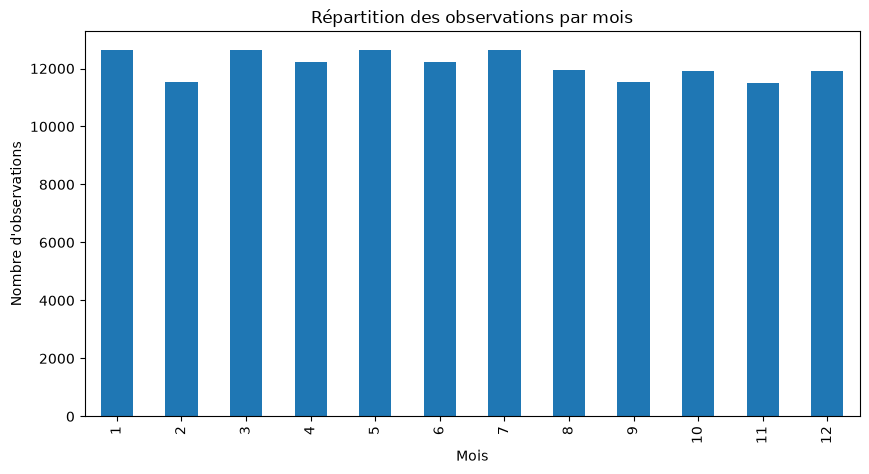

In [495]:
df["Month"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Répartition des observations par mois")
plt.xlabel("Mois")
plt.ylabel("Nombre d'observations")
plt.show()

In [496]:
df["Hour"].value_counts().sort_index()

Hour
0     6057
1     6058
2     6050
3     6041
4     6058
5     6058
6     6058
7     6058
8     6058
9     6058
10    6058
11    6058
12    6058
13    6058
14    6058
15    6058
16    6058
17    6058
18    6058
19    6058
20    6058
21    6058
22    6058
23    6058
Name: count, dtype: int64

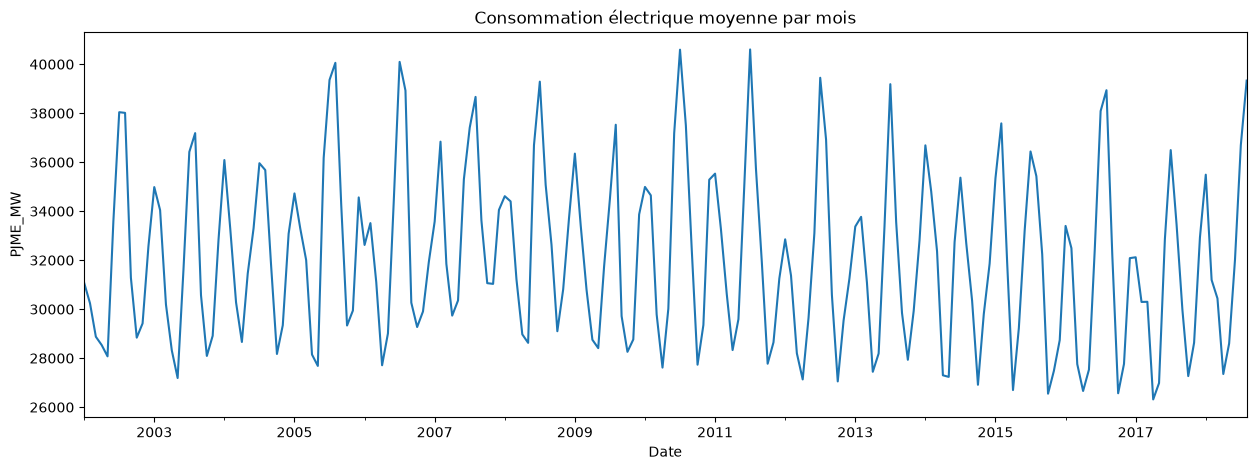

In [497]:
#time Serie Plot 
monthly = df.set_index("Datetime")["PJME_MW"].resample("ME").mean()  #resample() permet de regrouper les observations selon une fréquence temporelle.

monthly.plot(figsize=(15, 5))

plt.title("Consommation électrique moyenne par mois")
plt.xlabel("Date")
plt.ylabel("PJME_MW")
plt.show()

### Étape 2 : Nettoyage des données

In [498]:
print("duplicate values:", df.duplicated().sum())  #aucun valeur dupliquée
print("Value manquante:", df.isnull().sum())  #aucun valeur manquante

duplicate values: 0
Value manquante: Datetime    0
PJME_MW     0
Year        0
Month       0
Day         0
Hour        0
dtype: int64


In [499]:
print("duplicate dates:", df["Datetime"].duplicated().sum())  #date duplicate 

duplicates = df[df["Datetime"].duplicated(keep=False)]
duplicates.sort_values("Datetime")

duplicate dates: 4


,Datetime,PJME_MW,Year,Month,Day,Hour
106584,2014-11-02 02:00:00,22935.0,2014,11,2,2
106585,2014-11-02 02:00:00,23755.0,2014,11,2,2
115368,2015-11-01 02:00:00,21567.0,2015,11,1,2
115369,2015-11-01 02:00:00,21171.0,2015,11,1,2
124008,2016-11-06 02:00:00,20795.0,2016,11,6,2
124009,2016-11-06 02:00:00,21692.0,2016,11,6,2
132816,2017-11-05 02:00:00,21236.0,2017,11,5,2
132817,2017-11-05 02:00:00,20666.0,2017,11,5,2


In [500]:
#Remplace Duplicate observation par moyenne de la consommation électrique pour cette date
df = df.groupby("Datetime", as_index=False).agg({
    "PJME_MW": "mean"
})

In [501]:
#detection des outliers 
Q1 = df["PJME_MW"].quantile(0.25)
Q3 = df["PJME_MW"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["PJME_MW"] < lower_bound) |(df["PJME_MW"] > upper_bound)]

print("Nombre d'outliers :", len(outliers))

Nombre d'outliers : 3455


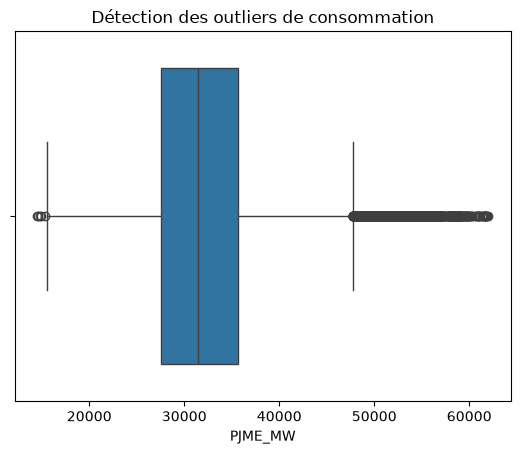

In [502]:
#Visualiser les outliers 
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df["PJME_MW"])

plt.title("Détection des outliers de consommation")
plt.show()

In [503]:
#Vérifier si les dates sont triées par ordre croissant
df["Datetime"].is_monotonic_increasing

True

### Étape 4 : Feature Engineering

In [504]:
# Convertir Datetime en datetime
df["Datetime"] = pd.to_datetime(df["Datetime"])

# Extraire les variables temporelles
df["Hour"] = df["Datetime"].dt.hour
df["DayOfWeek"] = df["Datetime"].dt.dayofweek
df["Month"] = df["Datetime"].dt.month
df["Year"] = df["Datetime"].dt.year

# Identifier le weekend
df["IsWeekend"] = (df["Datetime"].dt.dayofweek >= 5).astype(int)

In [505]:
df.head(10)

,Datetime,PJME_MW,Hour,DayOfWeek,Month,Year,IsWeekend
0,2002-01-01 01:00:00,30393.0,1,1,1,2002,0
1,2002-01-01 02:00:00,29265.0,2,1,1,2002,0
2,2002-01-01 03:00:00,28357.0,3,1,1,2002,0
3,2002-01-01 04:00:00,27899.0,4,1,1,2002,0
4,2002-01-01 05:00:00,28057.0,5,1,1,2002,0
5,2002-01-01 06:00:00,28654.0,6,1,1,2002,0
6,2002-01-01 07:00:00,29308.0,7,1,1,2002,0
7,2002-01-01 08:00:00,29595.0,8,1,1,2002,0
8,2002-01-01 09:00:00,29943.0,9,1,1,2002,0
9,2002-01-01 10:00:00,30692.0,10,1,1,2002,0


In [506]:
#Affiche les lags (variable de retard)

df["lag_24"]=df["PJME_MW"].shift(24) #consomation il ya 24h 
df["lag_168"]=df["PJME_MW"].shift(168) #consomation il ya 7jours 

df.head(25)

,Datetime,PJME_MW,Hour,DayOfWeek,Month,Year,IsWeekend,lag_24,lag_168
0,2002-01-01 01:00:00,30393.0,1,1,1,2002,0,NaN,NaN
1,2002-01-01 02:00:00,29265.0,2,1,1,2002,0,NaN,NaN
2,2002-01-01 03:00:00,28357.0,3,1,1,2002,0,NaN,NaN
3,2002-01-01 04:00:00,27899.0,4,1,1,2002,0,NaN,NaN
4,2002-01-01 05:00:00,28057.0,5,1,1,2002,0,NaN,NaN
5,2002-01-01 06:00:00,28654.0,6,1,1,2002,0,NaN,NaN
6,2002-01-01 07:00:00,29308.0,7,1,1,2002,0,NaN,NaN
7,2002-01-01 08:00:00,29595.0,8,1,1,2002,0,NaN,NaN
8,2002-01-01 09:00:00,29943.0,9,1,1,2002,0,NaN,NaN
9,2002-01-01 10:00:00,30692.0,10,1,1,2002,0,NaN,NaN


In [517]:
#Calcul moyene glissant 
df["roll_24"] = df["PJME_MW"].rolling(window=24).mean()
df.head(26)

,Datetime,PJME_MW,Hour,DayOfWeek,Month,Year,IsWeekend,lag_24,lag_168,roll_24
168,2002-01-08 01:00:00,29445.0,1,1,1,2002,0,26862.0,30393.0,NaN
169,2002-01-08 02:00:00,28670.0,2,1,1,2002,0,25976.0,29265.0,NaN
170,2002-01-08 03:00:00,28375.0,3,1,1,2002,0,25641.0,28357.0,NaN
171,2002-01-08 04:00:00,28542.0,4,1,1,2002,0,25666.0,27899.0,NaN
172,2002-01-08 05:00:00,29261.0,5,1,1,2002,0,26328.0,28057.0,NaN
173,2002-01-08 06:00:00,31348.0,6,1,1,2002,0,28267.0,28654.0,NaN
174,2002-01-08 07:00:00,35335.0,7,1,1,2002,0,31938.0,29308.0,NaN
175,2002-01-08 08:00:00,37841.0,8,1,1,2002,0,34678.0,29595.0,NaN
176,2002-01-08 09:00:00,37417.0,9,1,1,2002,0,35349.0,29943.0,NaN
177,2002-01-08 10:00:00,36824.0,10,1,1,2002,0,35542.0,30692.0,NaN


### Étape 5 : Préparation des données 

In [508]:
# Supprimer les lignes contenant des NaN
df = df.dropna()

In [509]:
features = [
    "Hour",
    "DayOfWeek",
    "Month",
    "Year",
    "IsWeekend",
    "lag_24",
    "lag_168",
    "roll_24"
]

X = df[features]
y = df["PJME_MW"]

In [510]:
#Séparation des données 
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=False
)

In [511]:
print("data training shape:", X_train.shape)
print("data test shape:", X_test.shape)

data training shape: (116155, 8)
data test shape: (29039, 8)


### Étape 6 : Entraînement et évaluation du modèle

In [512]:
#Entrainement de LinearRegression
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred_lr=lr_model.predict(X_test)


In [513]:
#utilise la consomation baseline 
y_pred_baseline=X_test["lag_24"]

In [514]:
#Evaluation de Prformence de Model de Régressin 
mae = mean_absolute_error(y_test, y_pred_lr)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2 = r2_score(y_test, y_pred_lr)
mape = mean_absolute_percentage_error(y_test, y_pred_lr) * 100

print("MAE :", mae)
print("RMSE :", rmse)
print("R² :", r2)
print("MAPE :", mape,"%")

MAE : 1814.4022730513902
RMSE : 2414.128554220039
R² : 0.8616907220166075
MAPE : 5.7471947789282245 %


In [515]:
#Evaluation de Prformence de baseline model
mae = mean_absolute_error(y_test, y_pred_baseline)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
r2 = r2_score(y_test, y_pred_baseline)
mape = mean_absolute_percentage_error(y_test, y_pred_baseline) * 100

print("MAE :", mae)
print("RMSE :", rmse)
print("R² :", r2)
print("MAPE :", mape,"%")

MAE : 2183.9943179861566
RMSE : 3008.9298548368015
R² : 0.7851404532362787
MAPE : 6.930153492412494 %


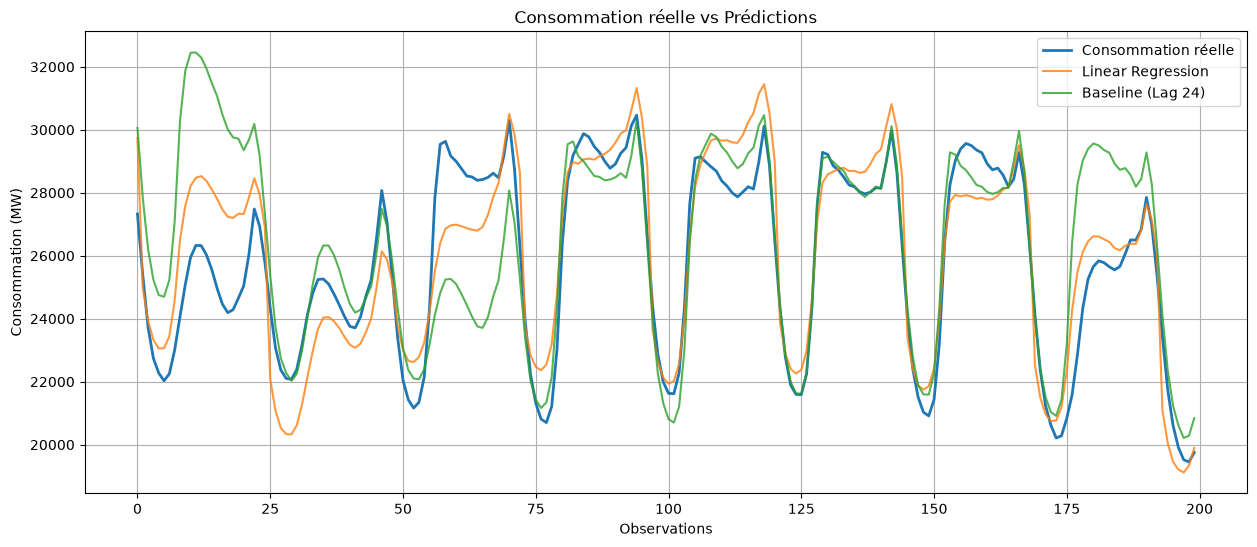

In [516]:
#Visualisation de Réel value et prédiction 
plt.figure(figsize=(15, 6))

# Valeurs réelles
plt.plot(
    y_test.iloc[:200].values,
    label="Consommation réelle",
    linewidth=2
)

# Prédictions Linear Regression
plt.plot(
    y_pred_lr[:200],
    label="Linear Regression",
    alpha=0.8
)

# Prédictions Baseline
plt.plot(
    y_pred_baseline.iloc[:200].values,
    label="Baseline (Lag 24)",
    alpha=0.8
)

plt.title("Consommation réelle vs Prédictions")
plt.xlabel("Observations")
plt.ylabel("Consommation (MW)")

plt.legend()
plt.grid()
plt.show()